# 04 Buyer replay

**Data:** chosen in `common.py` (`USE_FAKE_DATA`). Chart titles say whether it is real or fake.

A buyer picks **K styles every 4 weeks** to stock more of, then sees how they did over the next 4 weeks. Three buyers are compared:

1. **Model buyer:** the K styles with the highest *predicted* growth (what the app shows).
2. **Copy-last-month buyer:** the K styles that rose most over the *last* 4 weeks.
3. **Everything:** the average of all styles (a reference line).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from common import load_predictions, RISING_THRESHOLD, DATA_LABEL, MAIN_MODEL

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
MODEL, K = MAIN_MODEL, 10

df = load_predictions()
df = df[(df["model"] == MODEL) & (df["horizon"] == 4)].copy()

# What the copy-last-month buyer sees: growth over the last 4 weeks (recent_jump, from common.py).
df["last_month_growth"] = df["recent_jump"]
df = df.dropna(subset=["last_month_growth"])

# One decision every 4 weeks, so each set of picks is judged on its own 4 weeks.
first = df["origin"].min()
decision_dates = pd.date_range(first, df["origin"].max(), freq="28D")
print(f"{len(decision_dates)} decisions from {first.date()} to {decision_dates[-1].date()}, {K} picks each")

22 decisions from 2025-02-02 to 2026-09-13, 10 picks each


## Replay every decision

In [2]:
def judge(picks):
    return {"hit rate (%)": 100 * (picks["actual_growth"] > RISING_THRESHOLD).mean(),
            "average growth": picks["actual_growth"].mean()}

rows = []
for date in decision_dates:
    week = df[df["origin"] == date]
    rows.append({
        "date": date,
        **{f"model {k}": v for k, v in judge(week.nlargest(K, "predicted_growth")).items()},
        **{f"copy {k}": v for k, v in judge(week.nlargest(K, "last_month_growth")).items()},
        **{f"everything {k}": v for k, v in judge(week).items()},
    })
replay = pd.DataFrame(rows).set_index("date")
replay.round(2).head()

,model hit rate (%),model average growth,copy hit rate (%),copy average growth,everything hit rate (%),everything average growth
date,,,,,,
2025-02-02,60.0,1.21,30.0,1.15,6.98,1.01
2025-03-02,90.0,1.48,80.0,1.37,15.50,1.08
2025-03-30,50.0,1.23,40.0,1.14,5.47,1.02
2025-04-27,0.0,1.12,0.0,1.13,0.77,0.99
2025-05-25,30.0,1.14,10.0,1.05,3.08,1.02


## Summary

**Decisions won** = how many times the model buyer's picks grew more than the copy-last-month buyer's.

In [3]:
won = (replay["model average growth"] > replay["copy average growth"]).sum()
summary = pd.DataFrame({
    "Model buyer": [replay["model hit rate (%)"].mean(), replay["model average growth"].mean()],
    "Copy-last-month buyer": [replay["copy hit rate (%)"].mean(), replay["copy average growth"].mean()],
    "Everything": [replay["everything hit rate (%)"].mean(), replay["everything average growth"].mean()],
}, index=["average hit rate (%)", "average growth of picks"]).round(2)
print(f"Model buyer won {won} of {len(replay)} decisions against the copy-last-month buyer")
summary

Model buyer won 18 of 22 decisions against the copy-last-month buyer


,Model buyer,Copy-last-month buyer,Everything
average hit rate (%),57.73,35.45,20.90
average growth of picks,1.34,1.19,1.07


## Decision by decision

Average growth of each buyer's picks over the 4 weeks after each decision. Above 1.0 = the picks gained search interest.

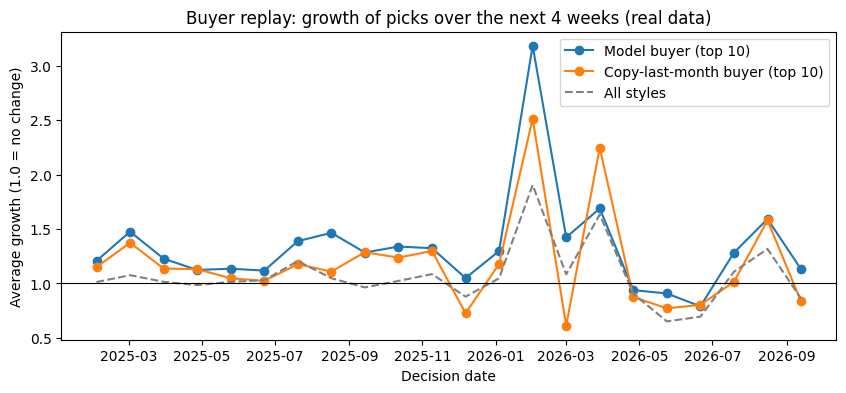

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(replay.index, replay["model average growth"], marker="o", label=f"Model buyer (top {K})")
ax.plot(replay.index, replay["copy average growth"], marker="o", label=f"Copy-last-month buyer (top {K})")
ax.plot(replay.index, replay["everything average growth"], linestyle="--", color="grey", label="All styles")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_title(f"Buyer replay: growth of picks over the next 4 weeks ({DATA_LABEL})")
ax.set_xlabel("Decision date")
ax.set_ylabel("Average growth (1.0 = no change)")
ax.legend()
fig.savefig(FIGURES / "04_buyer_replay.png", dpi=200, bbox_inches="tight")
plt.show()

## What this shows (will be shown once real results are in)

1. The model buyer won __ of __ decisions against copying last month's risers.
2. Average hit rate: __% vs. __%; average growth of picks: __ vs. __ (all styles: __).
3. Where the model buyer lost, and why (check those dates against notebooks 01–02):